**Step 1 — Import libraries**


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

**Step 2 — Load the dataset**

In [33]:
df=pd.read_csv('PJMW_hourly.csv')
df.head()

,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077.0
1,2002-12-31 02:00:00,4939.0
2,2002-12-31 03:00:00,4885.0
3,2002-12-31 04:00:00,4857.0
4,2002-12-31 05:00:00,4930.0


In [34]:
df.shape

(143206, 2)

In [35]:
print(df.columns)

Index(['Datetime', 'PJMW_MW'], dtype='object')


In [36]:
df.dtypes

,0
Datetime,object
PJMW_MW,float64


In [37]:
df.isnull().sum()

,0
Datetime,0
PJMW_MW,0


In [38]:
df.duplicated().sum()

np.int64(0)

**Outlier detection**

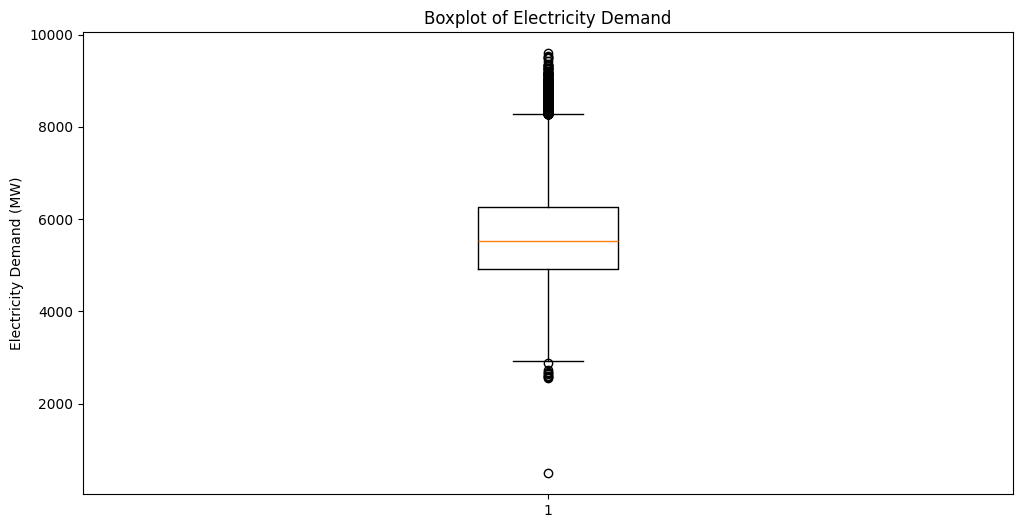

In [39]:
plt.figure(figsize=(12,6))

plt.boxplot(df['PJMW_MW'])
plt.ylabel("Electricity Demand (MW)")
plt.title('Boxplot of Electricity Demand')
plt.show()

In [40]:
Q1=df['PJMW_MW'].quantile(0.25)
Q3=df['PJMW_MW'].quantile(0.75)
IQR=Q3-Q1

lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR

outliers=df[(df['PJMW_MW']<lower_bound) | (df['PJMW_MW']>upper_bound)]
print("Number of potential outliers:", len(outliers))
print("Percentage:", len(outliers) / len(df) * 100)

Number of potential outliers: 703
Percentage: 0.4909012192226583


In [41]:
outliers_sorted = outliers.sort_values(
    'PJMW_MW',
    ascending=True
)

outliers_sorted.head(20)

,Datetime,PJMW_MW
11828,2003-05-29 00:00:00,487.0
92065,2012-04-02 00:00:00,2553.0
92057,2012-04-01 16:00:00,2574.0
92058,2012-04-01 17:00:00,2586.0
92059,2012-04-01 18:00:00,2600.0
92060,2012-04-01 19:00:00,2630.0
92056,2012-04-01 15:00:00,2663.0
92064,2012-04-01 23:00:00,2690.0
92055,2012-04-01 14:00:00,2721.0
92054,2012-04-01 13:00:00,2878.0


In [42]:
outliers['Datetime'] = pd.to_datetime(outliers['Datetime'])
outliers['hour'] = outliers['Datetime'].dt.hour
outliers['month'] = outliers['Datetime'].dt.month
print(outliers['hour'].value_counts().sort_index())
print(outliers['month'].value_counts().sort_index())

hour
0      7
1      2
2      1
3      1
4      1
5      7
6     14
7     35
8     50
9     45
10    32
11    22
12    16
13    21
14    34
15    42
16    57
17    58
18    68
19    66
20    52
21    38
22    23
23    11
Name: count, dtype: int64
month
1     275
2     124
3       8
4       9
5       1
6      29
7     118
8     106
12     33
Name: count, dtype: int64


### Outlier Distribution by Hour and Month

Let's visualize the distribution of detected outliers by hour of the day and month of the year to understand if outliers occur more frequently at specific times.

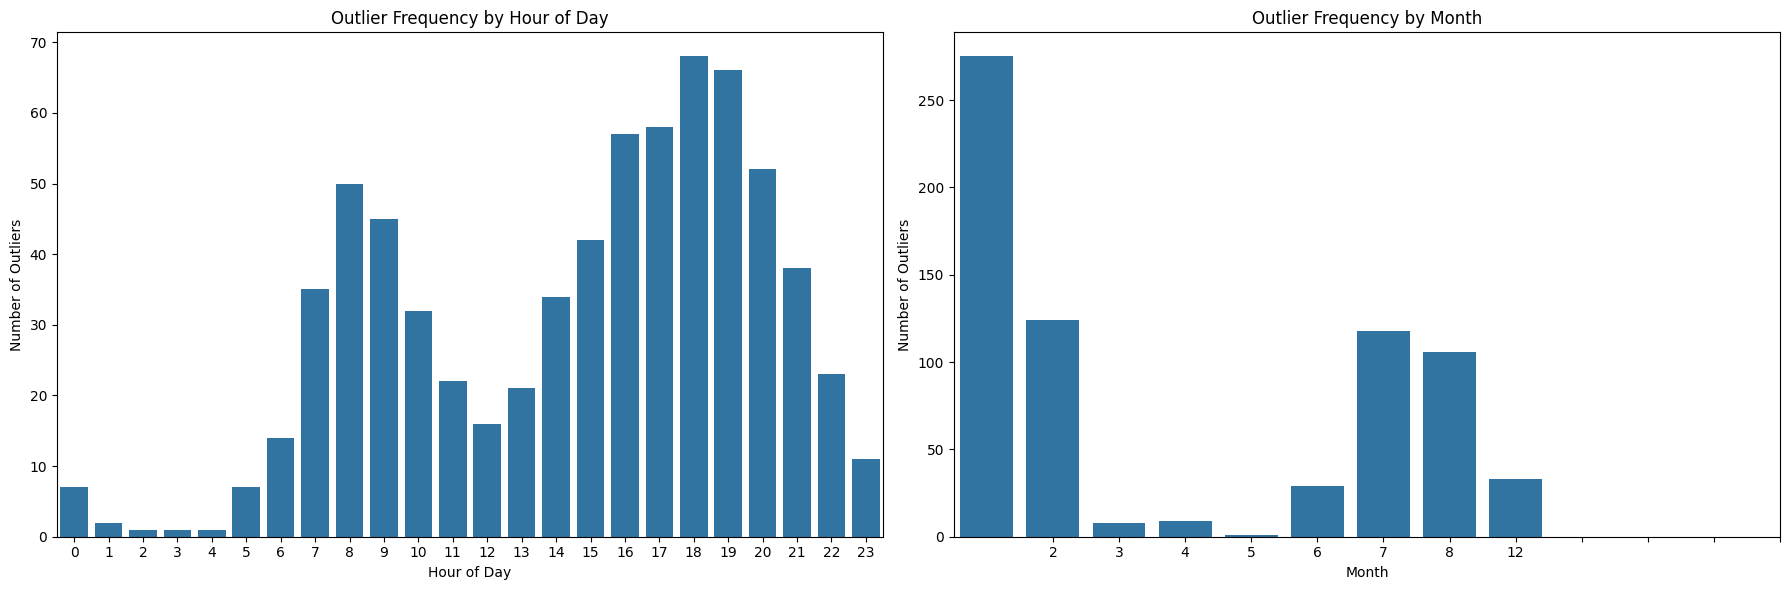

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(x=outliers['hour'].value_counts().index, y=outliers['hour'].value_counts().values, ax=axes[0])
axes[0].set_title('Outlier Frequency by Hour of Day')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Number of Outliers')
axes[0].set_xticks(range(0, 24))

sns.barplot(x=outliers['month'].value_counts().index, y=outliers['month'].value_counts().values, ax=axes[1])
axes[1].set_title('Outlier Frequency by Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Number of Outliers')
axes[1].set_xticks(range(1, 13))

plt.tight_layout()
plt.show()

In [44]:
df.loc[df['PJMW_MW'].idxmin()]

idx = df['PJMW_MW'].idxmin()
df.iloc[max(0, idx-5):idx+6]

,Datetime,PJMW_MW
11823,2003-05-28 19:00:00,5452.0
11824,2003-05-28 20:00:00,5487.0
11825,2003-05-28 21:00:00,5631.0
11826,2003-05-28 22:00:00,5746.0
11827,2003-05-28 23:00:00,5317.0
11828,2003-05-29 00:00:00,487.0
11829,2003-05-27 01:00:00,4103.0
11830,2003-05-27 02:00:00,4005.0
11831,2003-05-27 03:00:00,3989.0
11832,2003-05-27 04:00:00,4015.0


In [45]:
df['Demand_Change'] = df['PJMW_MW'].diff()
df['Pct_Change'] = df['PJMW_MW'].pct_change() * 100

df.loc[
    df['Demand_Change'].abs().nlargest(20).index,
    ['Datetime', 'PJMW_MW', 'Demand_Change', 'Pct_Change']
].sort_values('Demand_Change')

,Datetime,PJMW_MW,Demand_Change,Pct_Change
11828,2003-05-29 00:00:00,487.0,-4830.0,-90.840700
111623,2014-01-06 01:00:00,5446.0,-2657.0,-32.790325
128903,2016-01-17 01:00:00,5223.0,-2534.0,-32.667268
110303,2014-03-02 01:00:00,5333.0,-2421.0,-31.222595
142918,2018-01-12 01:00:00,4688.0,-2386.0,-33.729149
102263,2013-01-31 01:00:00,4700.0,-2382.0,-33.634567
142894,2018-01-13 01:00:00,5087.0,-2333.0,-31.442049
94201,2012-01-02 01:00:00,4738.0,-2303.0,-32.708422
137135,2017-02-08 01:00:00,4538.0,-2241.0,-33.057973
30041,2005-04-29 01:00:00,4884.0,-2195.0,-31.007204


In [46]:
anomaly_time = pd.Timestamp('2003-05-29 00:00:00')

df.loc[
    df['Datetime'] == anomaly_time,
    'PJMW_MW'
] = np.nan

df['PJMW_MW'] = df['PJMW_MW'].interpolate(
    method='linear'
)

### Impact of Outlier Imputation

After interpolating the anomalous data point, let's visualize the segment around the corrected anomaly to confirm the change. The anomaly was identified at `2003-05-29 00:00:00`.

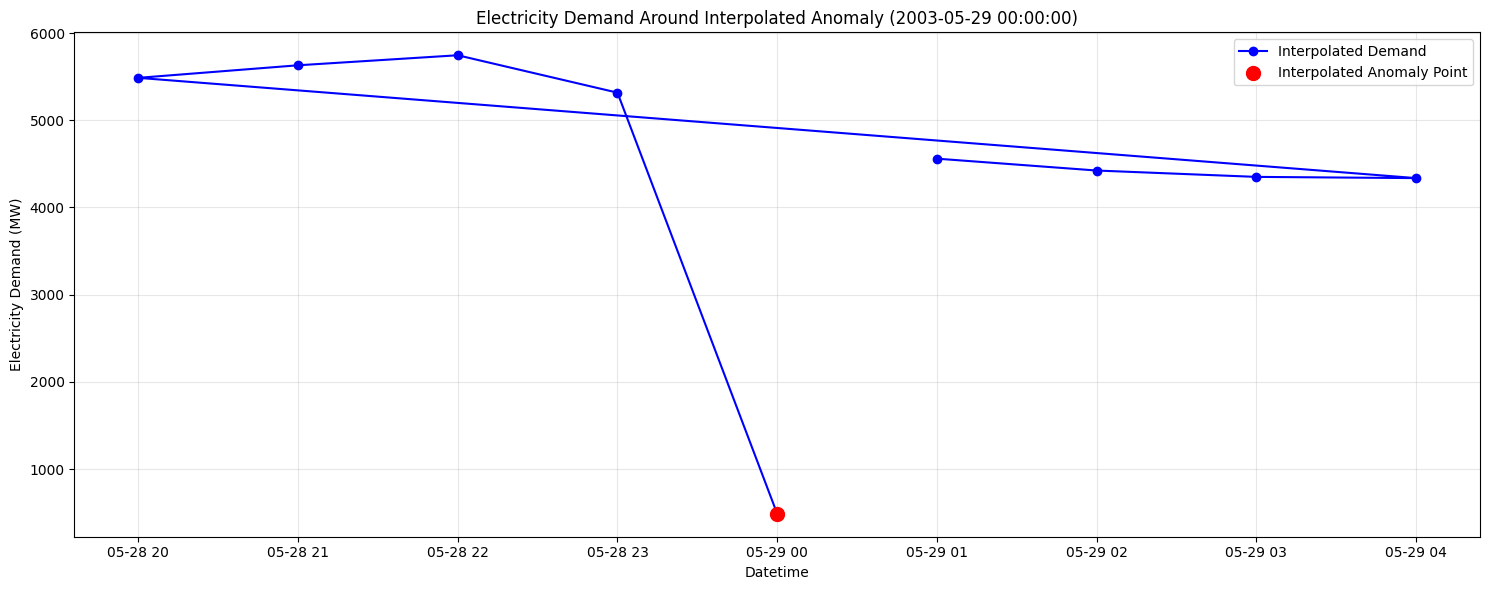

In [47]:
df['Datetime'] = pd.to_datetime(df['Datetime'])

plt.figure(figsize=(15, 6))
# Plot original data (if available or before interpolation, for comparison)
# For simplicity, we'll plot the data after interpolation and highlight the point

# Get a time window around the anomaly
anomaly_window_start = pd.Timestamp('2003-05-28 20:00:00')
anomaly_window_end = pd.Timestamp('2003-05-29 04:00:00')

window_df = df[(df['Datetime'] >= anomaly_window_start) & (df['Datetime'] <= anomaly_window_end)]

plt.plot(window_df['Datetime'], window_df['PJMW_MW'], marker='o', linestyle='-', color='blue', label='Interpolated Demand')
plt.scatter(anomaly_time, df.loc[df['Datetime'] == anomaly_time, 'PJMW_MW'], color='red', s=100, zorder=5, label='Interpolated Anomaly Point')

plt.title('Electricity Demand Around Interpolated Anomaly (2003-05-29 00:00:00)')
plt.xlabel('Datetime')
plt.ylabel('Electricity Demand (MW)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Step 4 — Convert Datetime**

In [48]:
df['Datetime']=pd.to_datetime(df['Datetime'])
df.dtypes

,0
Datetime,datetime64[ns]
PJMW_MW,float64
Demand_Change,float64
Pct_Change,float64


**Step 5 — Sort chronologically**

In [49]:
df=df.sort_values('Datetime').reset_index(drop=True)
df.head()

,Datetime,PJMW_MW,Demand_Change,Pct_Change
0,2002-04-01 01:00:00,4374.0,-320.0,-6.817213
1,2002-04-01 02:00:00,4306.0,-68.0,-1.554641
2,2002-04-01 03:00:00,4322.0,16.0,0.371575
3,2002-04-01 04:00:00,4359.0,37.0,0.856085
4,2002-04-01 05:00:00,4436.0,77.0,1.766460


In [50]:
df.tail()

,Datetime,PJMW_MW,Demand_Change,Pct_Change
143201,2018-08-02 20:00:00,6545.0,-148.0,-2.211266
143202,2018-08-02 21:00:00,6496.0,-49.0,-0.748663
143203,2018-08-02 22:00:00,6325.0,-171.0,-2.632389
143204,2018-08-02 23:00:00,5892.0,-433.0,-6.845850
143205,2018-08-03 00:00:00,5489.0,-403.0,-6.839783


**Step 6 — Check duplicate timestamps**

In [51]:
df['Datetime'].duplicated().sum()

np.int64(4)

In [52]:
duplicates=df[df['Datetime'].duplicated(keep=False)]
duplicates

,Datetime,PJMW_MW,Demand_Change,Pct_Change
110327,2014-11-02 02:00:00,4571.0,-42.0,-0.910470
110328,2014-11-02 02:00:00,4613.0,-192.0,-3.995838
119063,2015-11-01 02:00:00,3927.0,-87.0,-2.167414
119064,2015-11-01 02:00:00,3832.0,-95.0,-2.419149
127967,2016-11-06 02:00:00,4114.0,-144.0,-3.381869
127968,2016-11-06 02:00:00,4089.0,-25.0,-0.607681
136703,2017-11-05 02:00:00,3984.0,-58.0,-1.434933
136704,2017-11-05 02:00:00,4042.0,-148.0,-3.532220


In [53]:
df=(df.groupby('Datetime',as_index=False)['PJMW_MW'].mean())

In [54]:
df['Datetime'].duplicated().sum()

np.int64(0)

**Step 7- Check for the Time Intervals**

In [55]:
time_diff=df['Datetime'].diff()
time_diff.value_counts().head(10)

,count
Datetime,
0 days 01:00:00,143171
0 days 02:00:00,30


### Distribution of Time Intervals

Visualizing the `time_diff` will clearly show if there are any non-hourly intervals besides the few 2-hour differences that were detected, which usually indicates Daylight Saving Time changes.

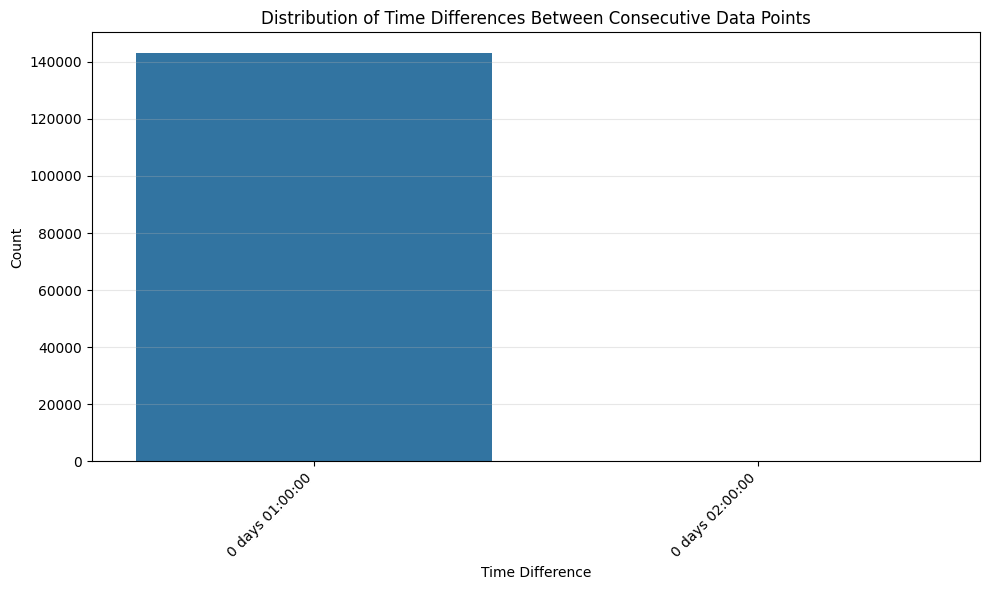

In [56]:
plt.figure(figsize=(10, 6))
time_diff_counts = time_diff.value_counts()
sns.barplot(x=time_diff_counts.index.astype(str), y=time_diff_counts.values)
plt.title('Distribution of Time Differences Between Consecutive Data Points')
plt.xlabel('Time Difference')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Step 8 — Basic statistics**

In [57]:
df['PJMW_MW'].describe()

,PJMW_MW
count,143202.000000
mean,5602.415755
std,979.125254
min,487.000000
25%,4907.000000
50%,5530.000000
75%,6252.000000
max,9594.000000


In [58]:
print("Minimum demand:", df['PJMW_MW'].min())
print("Maximum demand:", df['PJMW_MW'].max())
print("Average demand:", df['PJMW_MW'].mean())

Minimum demand: 487.0
Maximum demand: 9594.0
Average demand: 5602.415755366545


**Step 9 — Create time features**

In [59]:
df['hour']=df['Datetime'].dt.hour
df['dayofweek']=df['Datetime'].dt.dayofweek
df['day']=df['Datetime'].dt.day
df['month']=df['Datetime'].dt.month
df['year']=df['Datetime'].dt.year
df['dayofyear']=df['Datetime'].dt.dayofyear
df['IsWeekend'] = (df['dayofweek'] >= 5).astype(int)

**Overall Timeseries Plot**

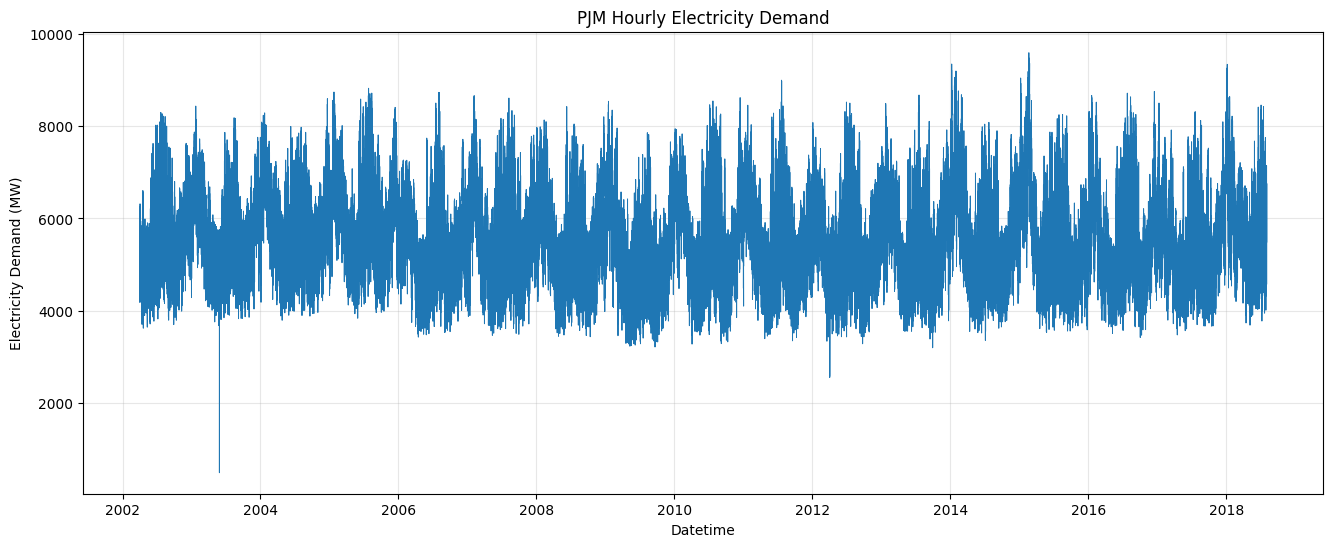

In [60]:
plt.figure(figsize=(16,6))

plt.plot(df['Datetime'],df['PJMW_MW'],linewidth=0.7)

plt.title('PJM Hourly Electricity Demand')
plt.xlabel('Datetime')
plt.ylabel('Electricity Demand (MW)')

plt.grid(True,alpha=0.3)
plt.show()

**One-Year Zoom**

There are more than 140000 points so the graph becomes Dense.

Zooming into one year allows us to see sessonal changes,summer peaks,winter behaviour,daily fluctuations and unusual periods much more clearly

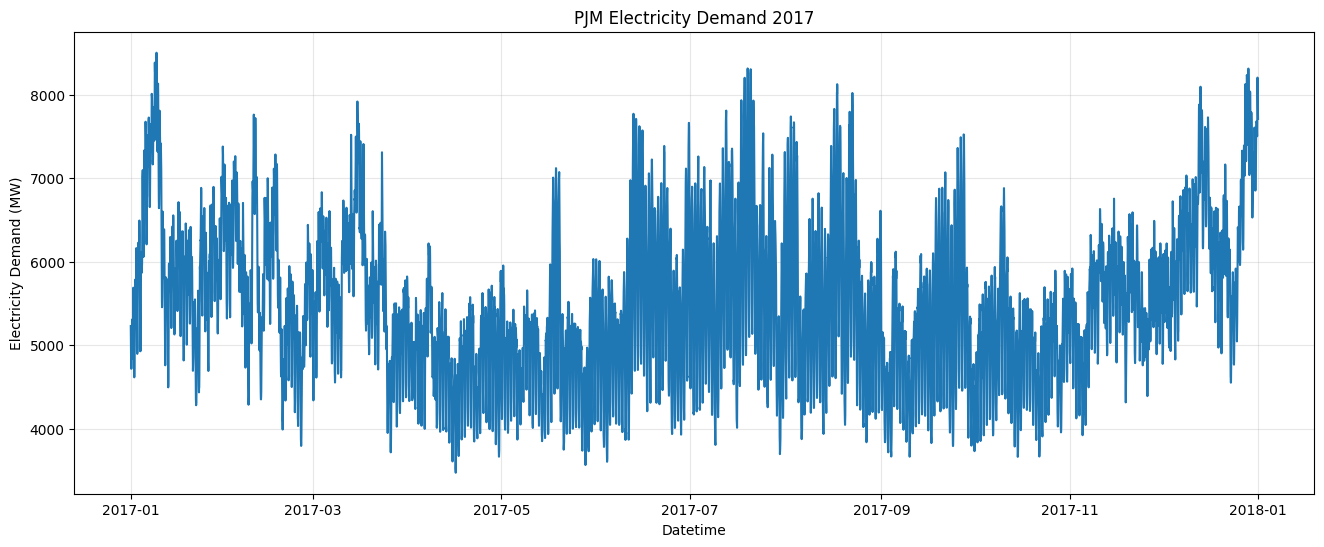

In [61]:
year_2017=df[df['year']==2017]

plt.figure(figsize=(16,6))

plt.plot(year_2017['Datetime'],
         year_2017['PJMW_MW'])

plt.title('PJM Electricity Demand 2017')

plt.xlabel('Datetime')
plt.ylabel('Electricity Demand (MW)')

plt.grid(True,alpha=0.3)
plt.show()

**Hour-of-Day Analysis**

Night

 ↓

People sleeping

 ↓

Lower electricity consumption


Morning

 ↓

People wake up

 ↓

Demand increases


Evening

 ↓

People return home

 ↓
Demand may increase

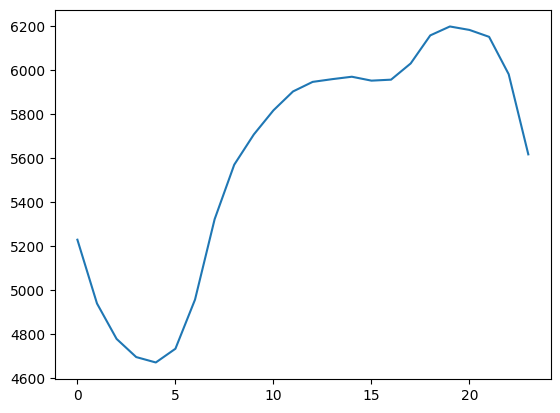

In [62]:
hourly_avg=(df.groupby('hour')['PJMW_MW'].mean())

plt.plot(hourly_avg.index,
         hourly_avg.values)

### Average Hourly Electricity Demand

This plot shows the average electricity demand over a 24-hour cycle. It helps in understanding the typical daily patterns of consumption.

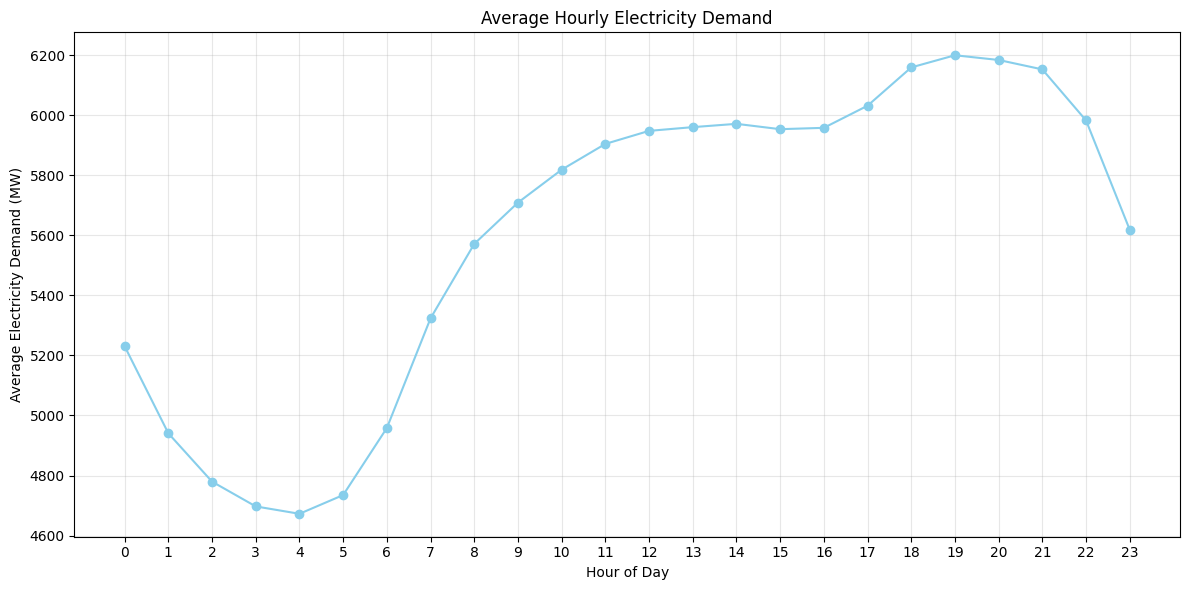

In [63]:
plt.figure(figsize=(12, 6))
plt.plot(hourly_avg.index, hourly_avg.values, marker='o', linestyle='-', color='skyblue')
plt.title('Average Hourly Electricity Demand')
plt.xlabel('Hour of Day')
plt.ylabel('Average Electricity Demand (MW)')
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Day-of-Week Analysis

In [64]:
weekly_avg=(df.groupby('dayofweek')['PJMW_MW'].mean())

### Average Electricity Demand by Day of Week

This bar chart illustrates how electricity demand varies across different days of the week, helping to identify weekly patterns such as higher demand on weekdays versus weekends.

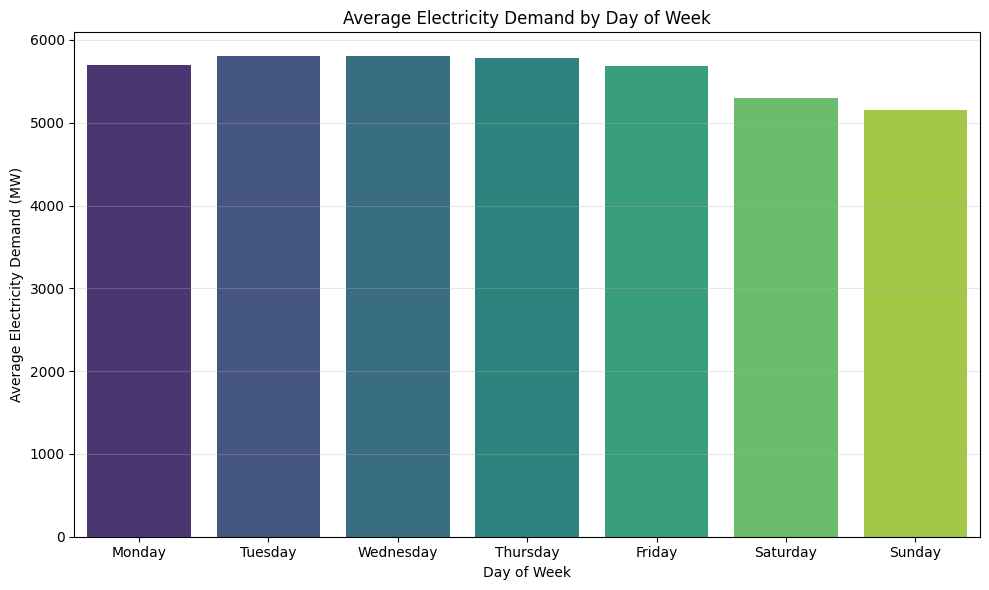

In [65]:
plt.figure(figsize=(10, 6))
weekly_avg_df = weekly_avg.reset_index()
weekly_avg_df['dayofweek_name'] = weekly_avg_df['dayofweek'].map({0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 4: 'Friday', 5: 'Saturday', 6: 'Sunday'})
sns.barplot(x='dayofweek_name', y='PJMW_MW', data=weekly_avg_df, palette='viridis')
plt.title('Average Electricity Demand by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Electricity Demand (MW)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 5. Hour × Day-of-Week Analysis

In [66]:
hour_day=df.pivot_table(values='PJMW_MW',index='hour',columns='dayofweek',aggfunc='mean')
hour_day

dayofweek,0,1,2,3,4,5,6
hour,,,,,,,
0,5036.051643,5330.651817,5364.967175,5357.437280,5348.674883,5205.454225,4968.916667
1,4792.493552,5034.437280,5064.416178,5061.423212,5047.160798,4896.971831,4686.298122
2,4676.717468,4871.892145,4898.303634,4895.751465,4878.413146,4713.881455,4518.135714
3,4625.826495,4791.808910,4816.087925,4814.690504,4795.311033,4616.784038,4413.378443
4,4625.635404,4773.962485,4796.584994,4792.913247,4771.491784,4572.684272,4374.138498
5,4722.240328,4859.350528,4879.528722,4871.808910,4844.322770,4588.480047,4378.341549
6,5008.641266,5147.001172,5158.650645,5151.430246,5106.062207,4689.426056,4445.511737
7,5465.298945,5616.758499,5627.273154,5616.162954,5544.238263,4840.338028,4552.759390
8,5746.415006,5879.864009,5884.920281,5874.589683,5807.815728,5054.713615,4748.568075


### Hourly Demand Heatmap by Day of Week

This heatmap provides a more detailed view of electricity demand, showing the interaction between the hour of the day and the day of the week. It's excellent for identifying specific peak and off-peak hours on different days.

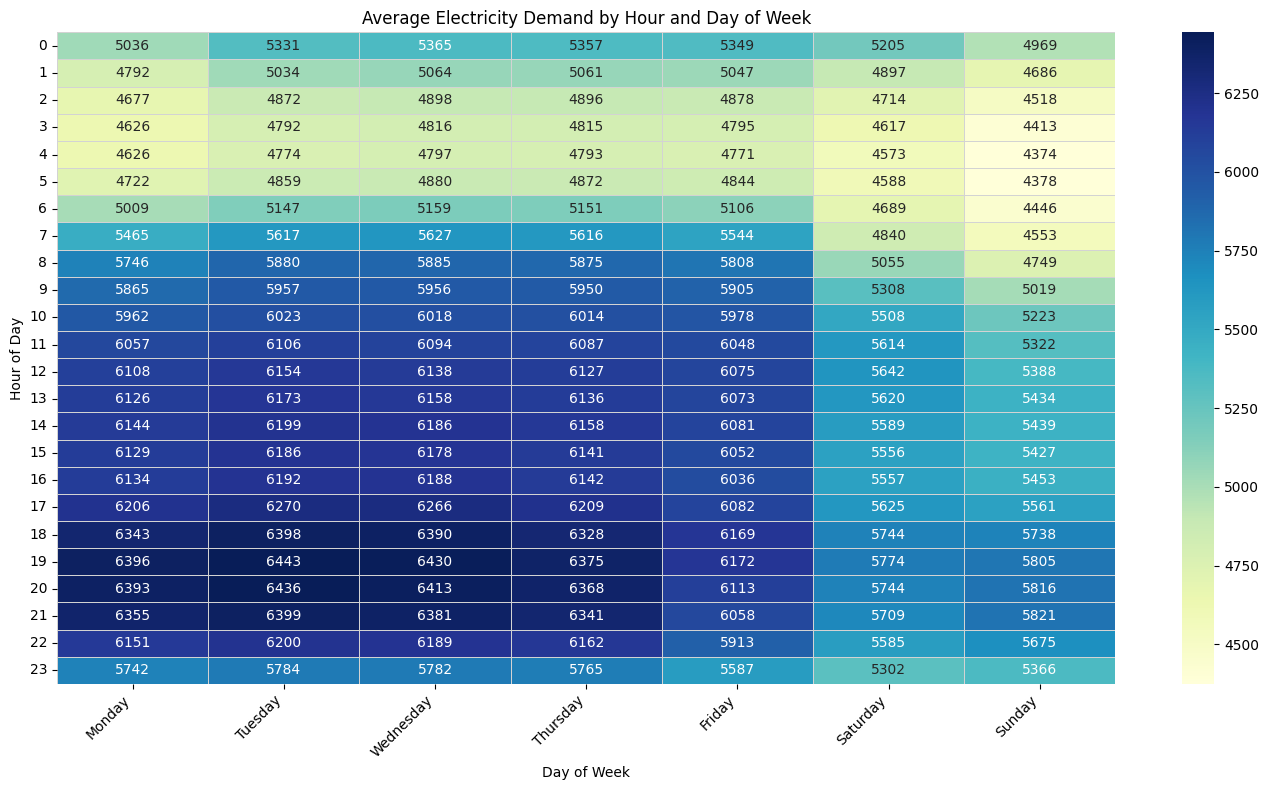

In [67]:
plt.figure(figsize=(14, 8))
sns.heatmap(hour_day, cmap='YlGnBu', annot=True, fmt=".0f", linewidths=.5, linecolor='lightgray')
plt.title('Average Electricity Demand by Hour and Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Hour of Day')
plt.xticks(ticks=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5], labels=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 6. Holiday Analysis

Our original dataset does not provide a holiday column.So we create one using U.S holiday column.

In [68]:
import holidays
us_holidays=holidays.US(years=range(df['year'].min(),df['year'].max()+1))

df['isHoliday']=df['Datetime'].dt.date.apply(lambda x: x in us_holidays)

In [69]:
### Is average electricity demand different on holidays compared with non-holidays

holidays_avg=(df.groupby('isHoliday')['PJMW_MW'].mean())

### Average Electricity Demand: Holidays vs. Non-Holidays

This bar chart compares the average electricity demand on holidays versus non-holidays, revealing whether public holidays significantly impact consumption patterns.

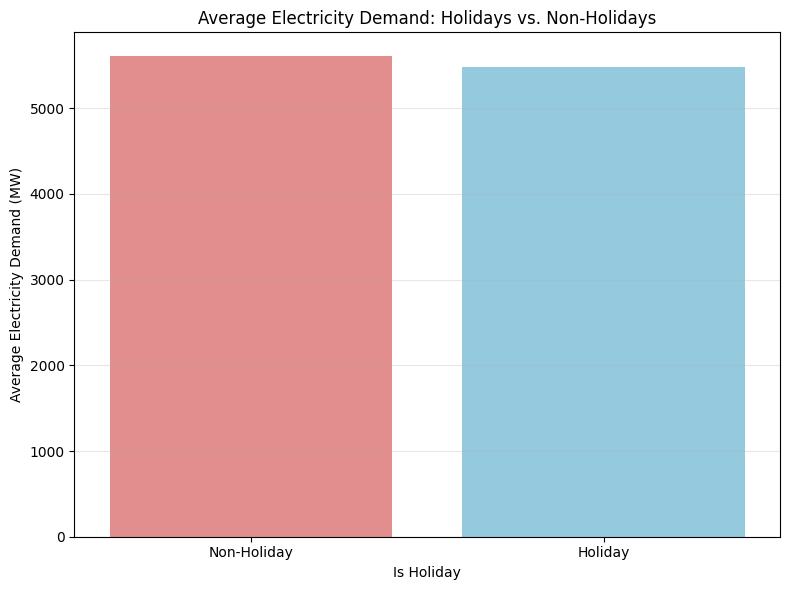

In [70]:
plt.figure(figsize=(8, 6))
holidays_avg_df = holidays_avg.reset_index()
sns.barplot(x='isHoliday', y='PJMW_MW', data=holidays_avg_df, palette=['lightcoral', 'skyblue'])
plt.title('Average Electricity Demand: Holidays vs. Non-Holidays')
plt.xlabel('Is Holiday')
plt.ylabel('Average Electricity Demand (MW)')
plt.xticks(ticks=[0, 1], labels=['Non-Holiday', 'Holiday'])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [71]:
def get_season(month):
  if month in [12,1,2]:
    return 'winter'
  elif month in [3,4,5]:
    return 'spring'
  elif month in [6,7,8]:
    return 'summer'
  else:
    return 'fall'

df['season']=df['month'].apply(get_season)

**Seasonal Hourly Analysis**

In [72]:
season_hour=(
    df.groupby(['season','hour'])['PJMW_MW']
    .mean()
    .reset_index()
)



### Seasonal Hourly Analysis: All Seasons

This plot extends the summer vs. winter comparison to include all four seasons. It helps in understanding how daily electricity demand patterns shift throughout the year due to different seasonal factors.

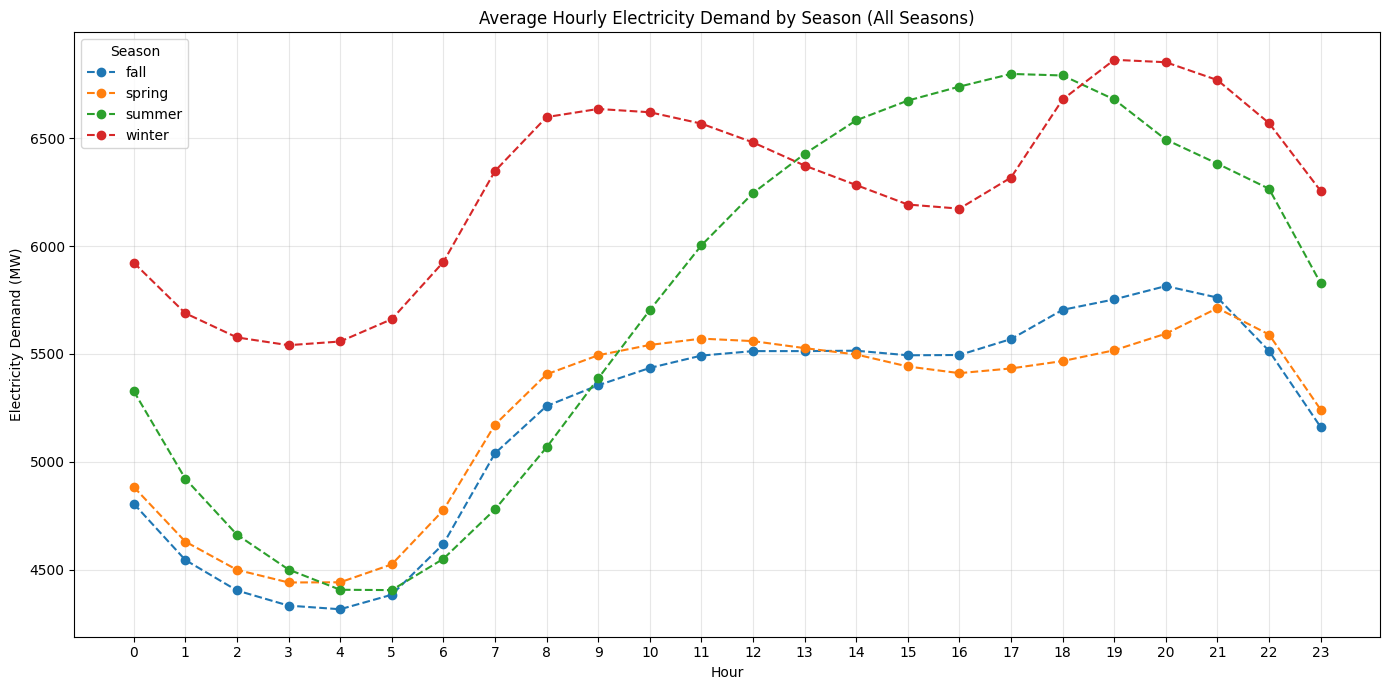

In [73]:
plt.figure(figsize=(14, 7))

for season_name in season_hour['season'].unique():
    season_data = season_hour[season_hour['season'] == season_name]
    plt.plot(
        season_data['hour'],
        season_data['PJMW_MW'],
        label=season_name,
        marker='o', linestyle='--'
    )

plt.xlabel('Hour')
plt.ylabel('Electricity Demand (MW)')
plt.title('Average Hourly Electricity Demand by Season (All Seasons)')
plt.xticks(range(0, 24))
plt.legend(title='Season')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Summer vs Winter Direct Comparison**

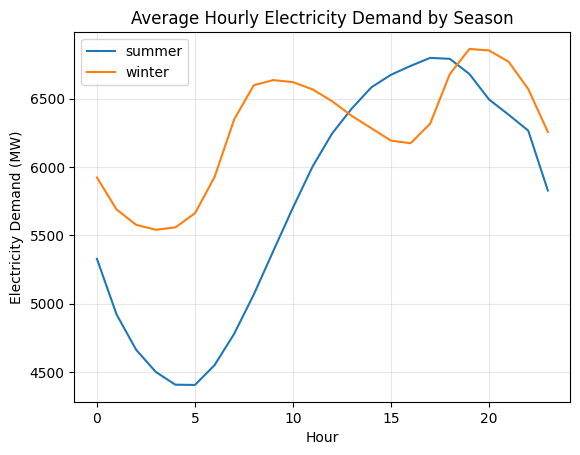

In [74]:
summer = season_hour[season_hour['season'] == 'summer']
winter = season_hour[season_hour['season'] == 'winter']

plt.plot(
    summer['hour'],
    summer['PJMW_MW'],
    label='summer'
)

plt.plot(
    winter['hour'],
    winter['PJMW_MW'],
    label='winter'
)

plt.xlabel('Hour')
plt.ylabel('Electricity Demand (MW)')
plt.title('Average Hourly Electricity Demand by Season')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Monthly Seasonality**

In [75]:
monthly_avg = (
    df.groupby('month')['PJMW_MW']
      .mean()
)

### Monthly Seasonality of Electricity Demand

This line plot illustrates the average electricity demand for each month of the year. It helps identify annual cycles and high-demand months, often linked to extreme weather conditions.

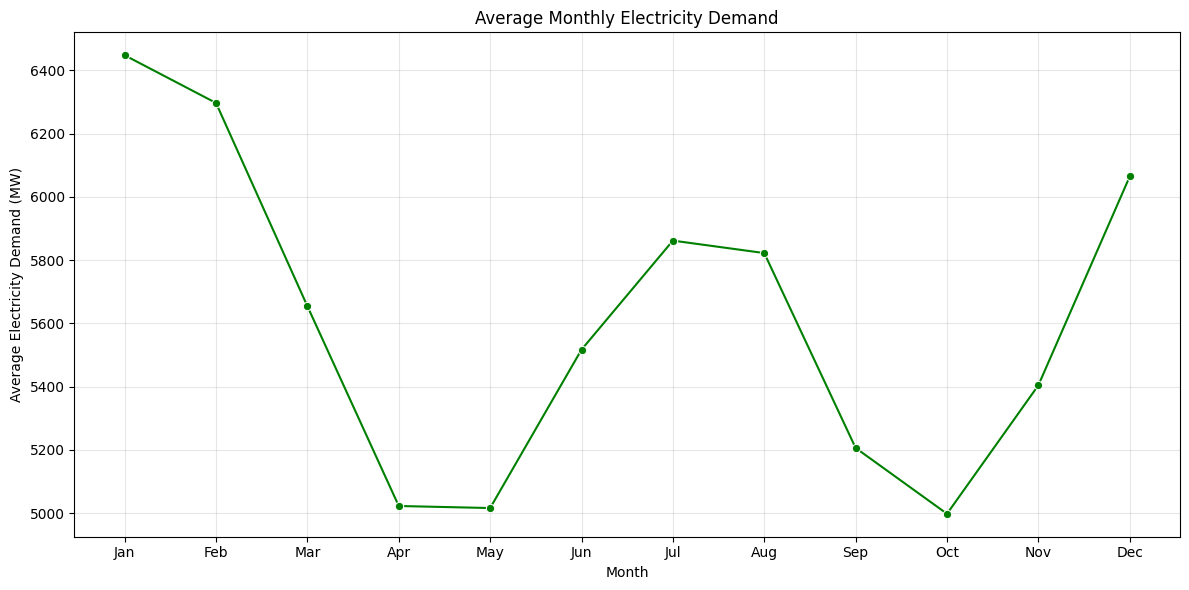

In [76]:
plt.figure(figsize=(12, 6))
monthly_avg_df = monthly_avg.reset_index()
sns.lineplot(x='month', y='PJMW_MW', data=monthly_avg_df, marker='o', color='green')
plt.title('Average Monthly Electricity Demand')
plt.xlabel('Month')
plt.ylabel('Average Electricity Demand (MW)')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Long Term Yealy Trend**

In [77]:
yearly_avg = (
    df.groupby('year')['PJMW_MW']
      .mean()
)

### Long-Term Yearly Trend of Electricity Demand

This line plot visualizes the average electricity demand for each year in the dataset. It helps in observing long-term trends, such as growth or decline in overall consumption over the years.

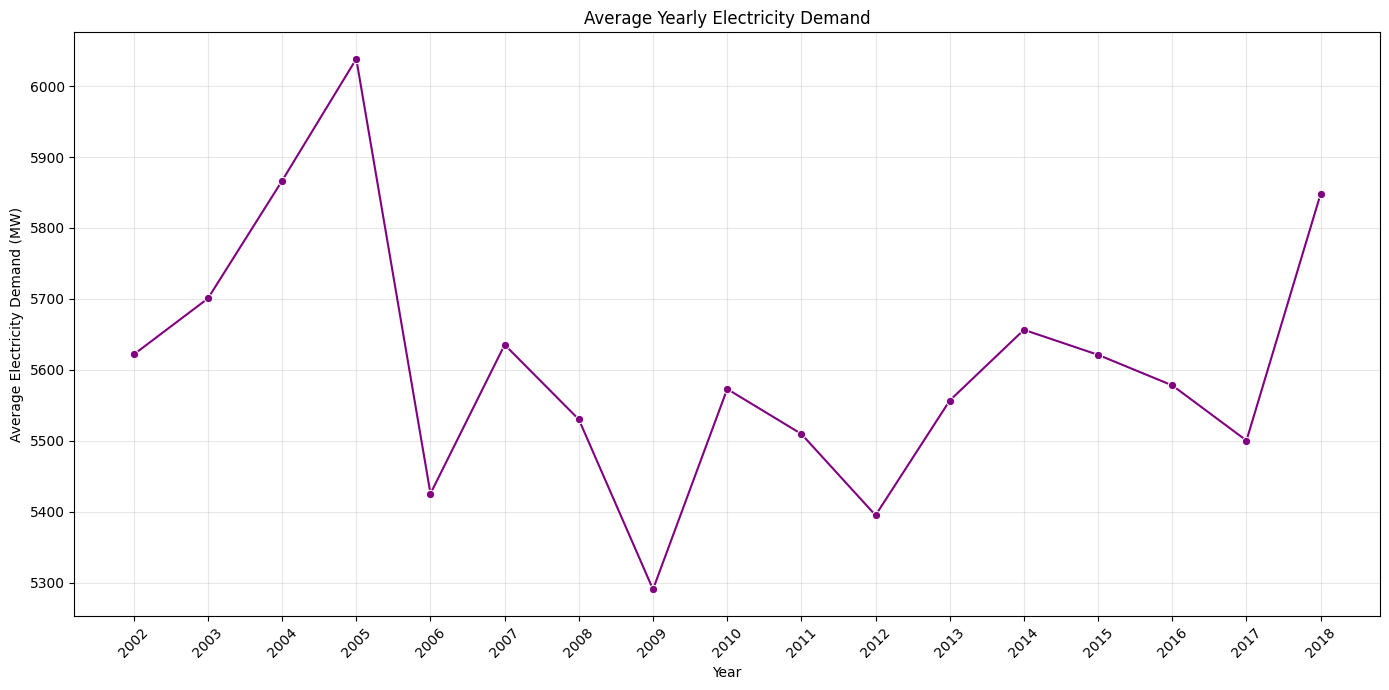

In [78]:
plt.figure(figsize=(14, 7))
yearly_avg_df = yearly_avg.reset_index()
sns.lineplot(x='year', y='PJMW_MW', data=yearly_avg_df, marker='o', color='purple')
plt.title('Average Yearly Electricity Demand')
plt.xlabel('Year')
plt.ylabel('Average Electricity Demand (MW)')
plt.xticks(yearly_avg_df['year'].unique(), rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()